In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RNG_SEED = 42
np.random.seed(RNG_SEED)

In [22]:
file_path = '/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv'
churn_raw = pd.read_csv(file_path)
churn_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Task 01 - Exploratory Data Analysis

In [23]:
print("Shape:", churn_raw.shape)
print("Column data types:", churn_raw.dtypes)
print("Missing values per column:", churn_raw.isnull().sum())
print("Duplicate rows:", churn_raw.duplicated().sum())


Shape: (7043, 21)
Column data types: customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
Missing values per column: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Cont

In [24]:
churn_raw["TotalCharges"] = pd.to_numeric(churn_raw["TotalCharges"], errors="coerce")
print("Rows with TotalCharges now NaN after coercion:", churn_raw["TotalCharges"].isnull().sum())

churn_raw.describe(include="all").T

Rows with TotalCharges now NaN after coercion: 11


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


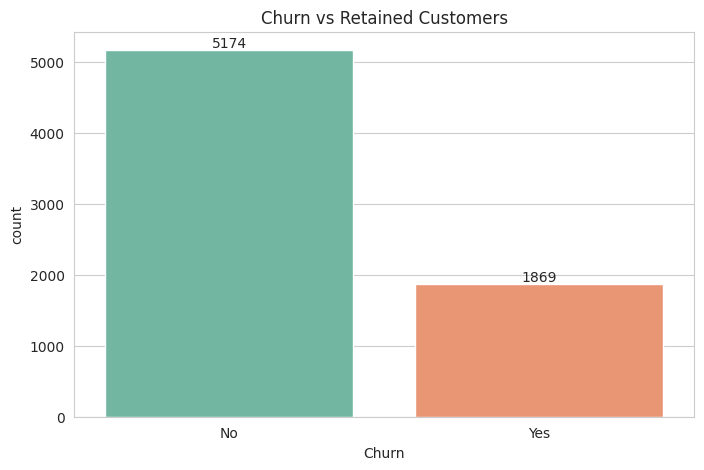

In [25]:
target_counts = churn_raw["Churn"].value_counts(normalize=True) * 100
print(target_counts)

fig, ax = plt.subplots()
sns.countplot(data=churn_raw, x="Churn", palette="Set2", ax=ax)
ax.set_title("Churn vs Retained Customers")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

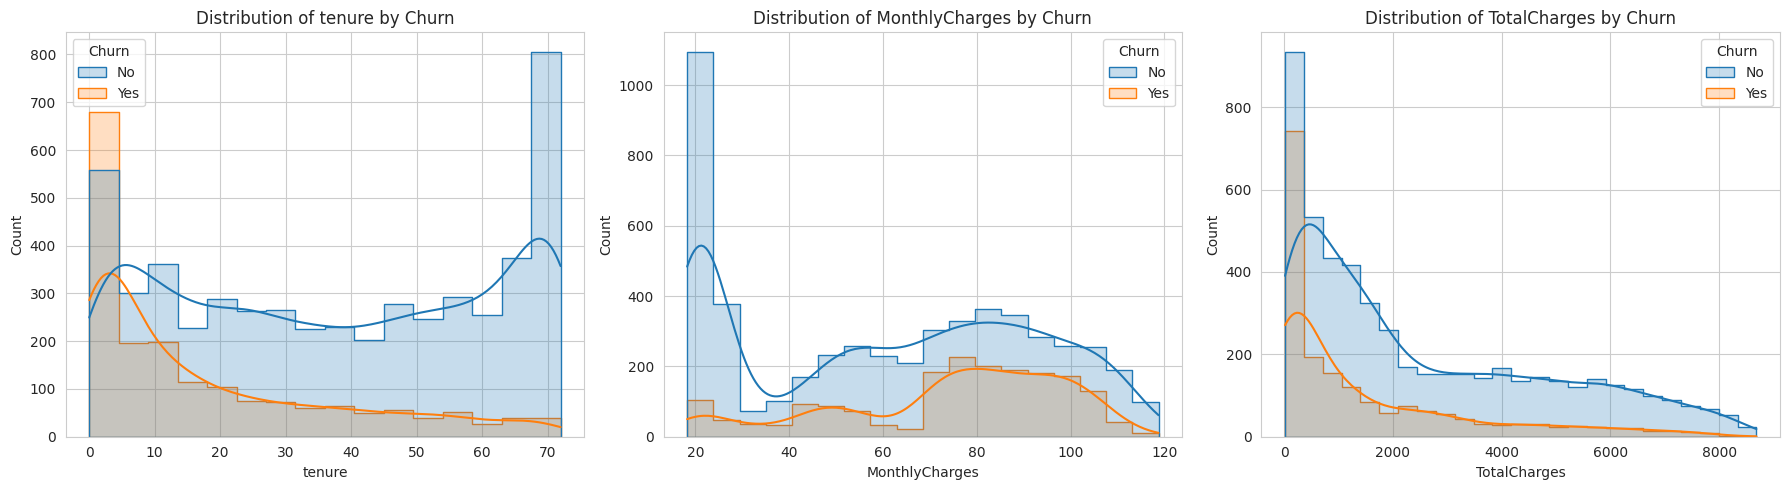

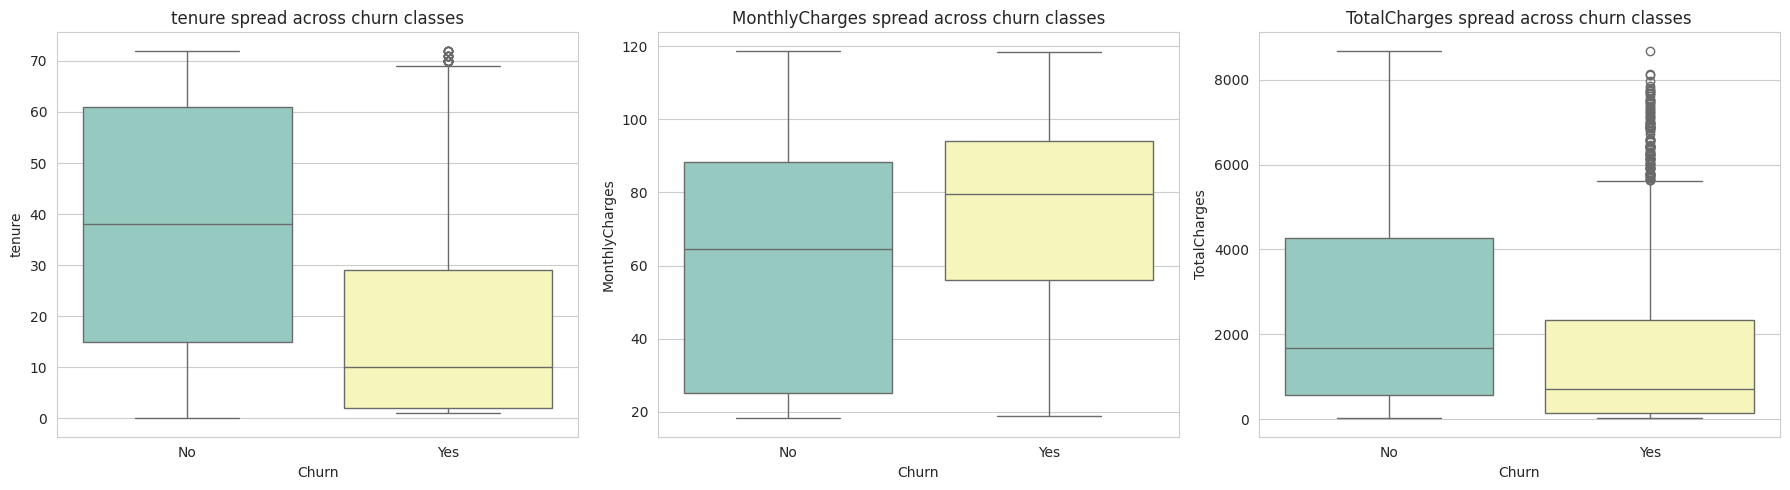

In [26]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for col, ax in zip(numeric_cols, axes):
    sns.histplot(data=churn_raw, x=col, hue="Churn", kde=True, element="step", ax=ax)
    ax.set_title(f"Distribution of {col} by Churn")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for col, ax in zip(numeric_cols, axes):
    sns.boxplot(data=churn_raw, x="Churn", y=col, palette="Set3", ax=ax)
    ax.set_title(f"{col} spread across churn classes")
plt.tight_layout()
plt.show()

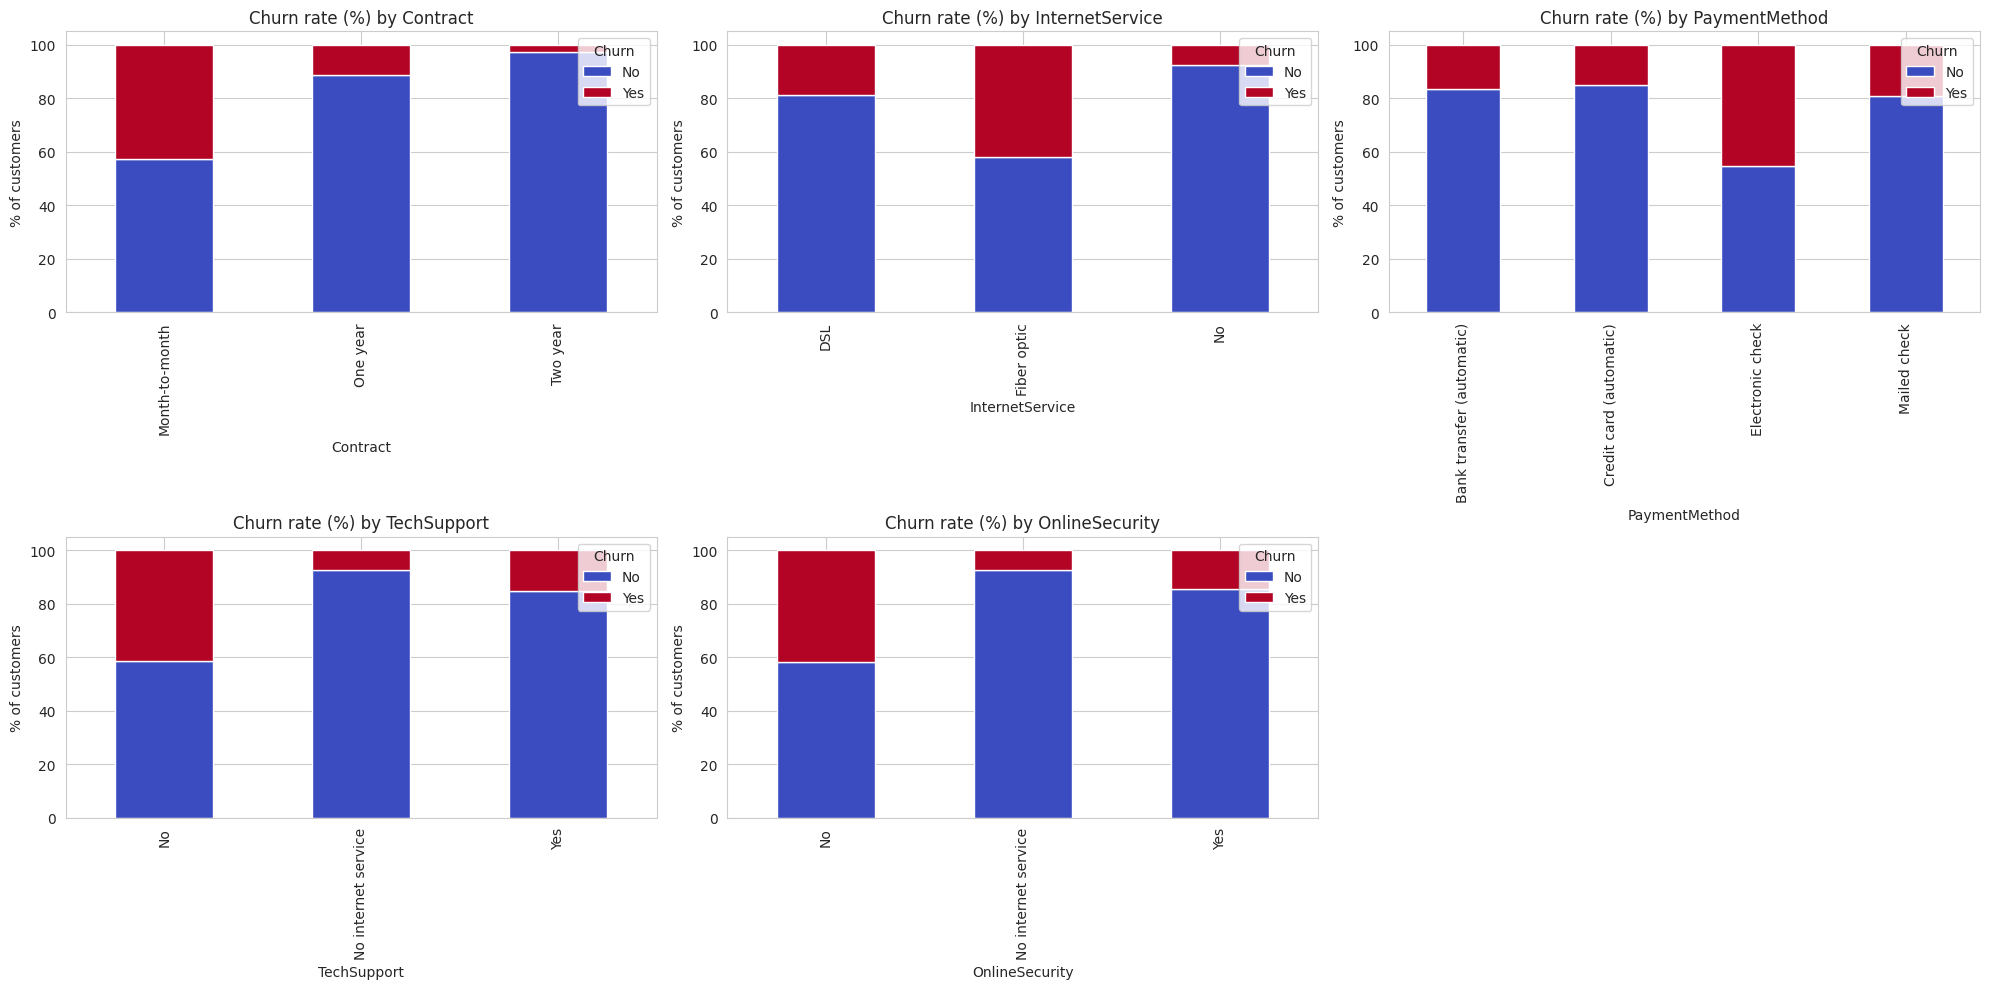

In [27]:
categorical_focus = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()
for col, ax in zip(categorical_focus, axes):
    cross_tab = pd.crosstab(churn_raw[col], churn_raw["Churn"], normalize="index") * 100
    cross_tab.plot(kind="bar", stacked=True, ax=ax, colormap="coolwarm")
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_ylabel("% of customers")
    ax.legend(title="Churn", loc="upper right")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


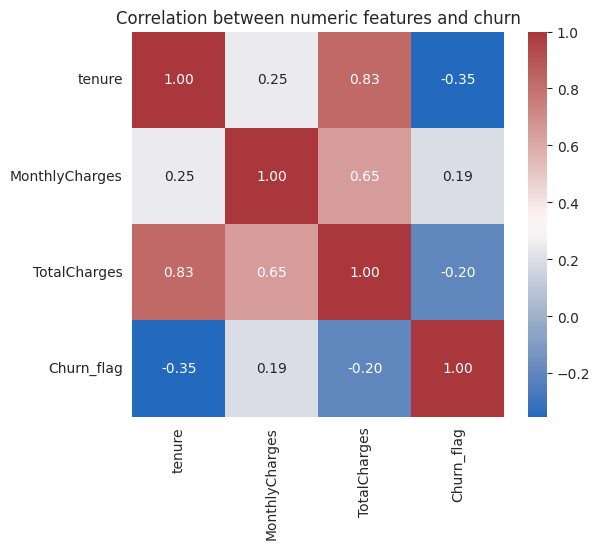

In [28]:
corr_frame = churn_raw.copy()
corr_frame["Churn_flag"] = corr_frame["Churn"].map({"Yes": 1, "No": 0})
corr_matrix = corr_frame[numeric_cols + ["Churn_flag"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="vlag", fmt=".2f")
plt.title("Correlation between numeric features and churn")
plt.show()